# Model Evaluation: Financial Resilience

This notebook is for model evaluation to evauluate how well the model identifies respondents who
cannot cover a $400 emergency expense using cash or the equivalent.

The performance is assessed using accuracy, precision, recall, ROC AUC,
a confusion matrix, and comparison with baselines. Survey weights are used for the evaluation, and the team's saved train/test split is preserved.

The positive class is financially fragile represented by 1, while the negative class is not financially fragile reperesented by 0.

In [28]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

In [29]:
uploaded = files.upload()

Saving model_dataset_2025_spec.json to model_dataset_2025_spec (1).json
Saving model_dataset_2025.csv to model_dataset_2025 (1).csv


In [30]:
DATASET_PATH = "/content/model_dataset_2025.csv"
SPEC_PATH = "/content/model_dataset_2025_spec.json"

data = pd.read_csv(DATASET_PATH, low_memory=False)

with open(SPEC_PATH, "r", encoding="utf-8") as f:
    spec = json.load(f)

print(f"Dataset loaded: {data.shape[0]:,} rows and {data.shape[1]:,} columns")
print("Model dataset has loaded successfully.")

Dataset loaded: 12,934 rows and 430 columns
Model dataset has loaded successfully.


In [31]:
Target = spec["target"]["column"]
Weight = spec["weight"]

Features = (
    spec["features"]["numeric"]
    + spec["features"]["categorical"]
    + spec["features"]["ordinal"]
)

print(f"Target column name: {Target}")
print(f"Survey weight column name: {Weight}")
print(f"Number of predictors: {len(Features)}")

Target column name: financially_fragile
Survey weight column name: weight_pop
Number of predictors: 425


In [32]:
train = data[data["split"] == "train"].copy()
test = data[data["split"] == "test"].copy()

X_train = train[Features]
y_train = train[Target]
w_train = train[Weight]

X_test = test[Features]
y_test = test[Target]
w_test = test[Weight]

print(f"Number of training respondents: {len(train):,}")
print(f"Number of testing respondents: {len(test):,}")
print(f"Numbers of predictors per respondent: {X_test.shape[1]:,}")

Number of training respondents: 10,347
Number of testing respondents: 2,587
Numbers of predictors per respondent: 425


In [33]:
training_fragile_rate = np.average(y_train, weights=w_train)

majority_class = int(training_fragile_rate >= 0.5)

baseline_predictions = np.full(len(y_test), majority_class)

baseline_results = pd.DataFrame({
    "Model": ["Common class baseline"],
    "Accuracy": [
        accuracy_score(y_test, baseline_predictions, sample_weight=w_test)
    ],
    "Precision": [
        precision_score(
            y_test, baseline_predictions,
            sample_weight=w_test, zero_division=0
        )
    ],
    "Recall": [
        recall_score(
            y_test, baseline_predictions,
            sample_weight=w_test, zero_division=0
        )
    ],
})

print(f"The baseline predicted class: {majority_class}")
display(baseline_results.round(3))

The baseline predicted class: 0


,Model,Accuracy,Precision,Recall
0,Common class baseline,0.63,0.0,0.0


In [34]:
test_prediction_upload = files.upload()

Saving logistic_test_predictions.csv to logistic_test_predictions (1).csv


In [35]:
prediction_data = pd.read_csv(
    "/content/logistic_test_predictions.csv"
)

assert prediction_data["shedid"].is_unique, "Duplicate prediction IDs have been found."

assert set(prediction_data["shedid"]) == set(test["shedid"]), \
    "Prediction IDs do not match the test set IDs."

matched_predictions = (
    prediction_data
    .set_index("shedid")
    .loc[test["shedid"]]
)

assert np.array_equal(
    matched_predictions["actual_fragile"].to_numpy(),
    y_test.to_numpy()
), "Actual labels do not match."

p_test = pd.Series(
    matched_predictions["predicted_probability"].to_numpy(),
    index=test.index,
    name="p_fragile"
)

assert p_test.notna().all() and p_test.between(0, 1).all(), \
    "Predictions must be valid probabilities."

print(f"Successfully matched {len(p_test):,} test predictions.")

Successfully matched 2,587 test predictions.


In [36]:
Threshold = 0.5
model_predictions = (p_test >= Threshold).astype(int)

model_results = pd.DataFrame({
    "Model": ["Logistic regression"],
    "Accuracy": [
        accuracy_score(y_test, model_predictions, sample_weight=w_test)
    ],
    "Precision": [
        precision_score(
            y_test, model_predictions,
            sample_weight=w_test, zero_division=0
        )
    ],
    "Recall": [
        recall_score(
            y_test, model_predictions,
            sample_weight=w_test, zero_division=0
        )
    ],
    "ROC AUC": [
        roc_auc_score(y_test, p_test, sample_weight=w_test)
    ],
})

baseline_results["ROC AUC"] = roc_auc_score(
    y_test,
    baseline_predictions,
    sample_weight=w_test
)

comparison_results = pd.concat(
    [baseline_results, model_results],
    ignore_index=True
)

display(comparison_results.round(3))

,Model,Accuracy,Precision,Recall,ROC AUC
0,Common class baseline,0.630,0.000,0.00,0.500
1,Logistic regression,0.856,0.821,0.78,0.925


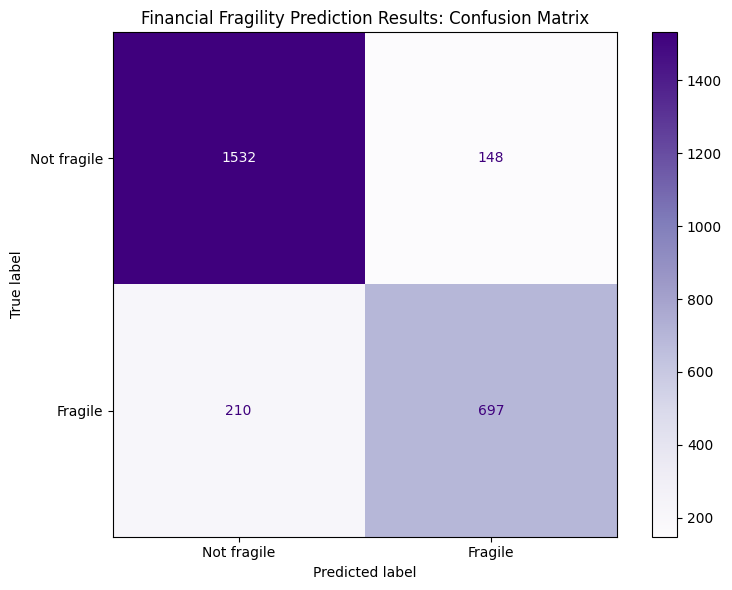

In [37]:
matrix = confusion_matrix(
    y_test,
    model_predictions,
    labels=[0, 1]
)

matrix_display = ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=["Not fragile", "Fragile"]
)

fig, ax = plt.subplots(figsize=(8, 6))

matrix_display.plot(
    ax=ax,
    cmap="Purples",
    values_format="d",
    colorbar=True
)

ax.set_title("Financial Fragility Prediction Results: Confusion Matrix")
plt.tight_layout()
plt.show()

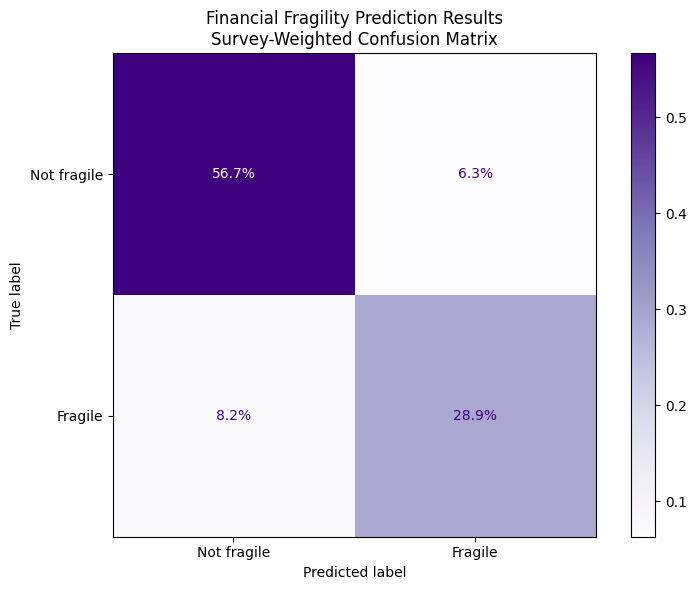

In [38]:
weighted_matrix = confusion_matrix(
    y_test,
    model_predictions,
    labels=[0, 1],
    sample_weight=w_test,
    normalize="all"
)

weighted_display = ConfusionMatrixDisplay(
    confusion_matrix=weighted_matrix,
    display_labels=["Not fragile", "Fragile"]
)

fig, ax = plt.subplots(figsize=(8, 6))

weighted_display.plot(
    ax=ax,
    cmap="Purples",
    values_format=".1%",
    colorbar=True
)

ax.set_title(
    "Financial Fragility Prediction Results\n"
    "Survey-Weighted Confusion Matrix"
)

plt.tight_layout()
plt.show()

## Confusion Matrix Results

At the 0.50 probability threshold, the model correctly was able to classify
1,532 respondents as not financially fragile and 697 as financially
fragile. The model incorrectly classified 148 respondents as fragile, which is false positives, and missed 210 respondents who were actually
fragile being false negatives.

After applying survey weights, the correct predictions account for
approximately 85.6% of the weighted test population, false positives
account for 6.3%, while the false negatives account for 8.2%.

These percentages describe shares of the total weighted test
population, rather than error rates within each class. The missed
fragile respondents show why accuracy alone is not sufficient
to assess model performance and why it is important to further evaluate the model.

In [39]:
display(comparison_results.round(3))

,Model,Accuracy,Precision,Recall,ROC AUC
0,Common class baseline,0.630,0.000,0.00,0.500
1,Logistic regression,0.856,0.821,0.78,0.925


## Model Performance Summary

Logistic regression achieved a survey-weighted accuracy of 85.6%,
compared to 63.0% for the common class baseline, which has an improvement
of 22.6 percentage points.

At the 0.50 threshold, precision was 82.1%, meaning that approximately
82% of respondents predicted to be financially fragile were actually
fragile. Recall was 78.0%, meaning the model identified approximately
78% of actual fragile cases and missed about 22%.

ROC AUC was 0.925, compared to 0.500 for the baseline, indicating a strong ability to rank fragile respondents above non-fragile respondents.

The baseline always predicted not fragile and therefore identified
none of the fragile cases. Its precision is undefined because it made
no fragile predictions; the code reports this as 0.

Overall, this model performs better than the common class baseline, but its
missed fragile cases demonstrate that its predictions remain imperfect and there is room for improvement.

## Model Limitations

- The limited definition of resilience: The target measures whether someone
  can cover a $400 emergency expense with cash or its equivalent.
  This does not capture every aspect of financial resilience.

- Self-reported data from respondents: Survey responses may contain reporting errors
  or differences in how respondents interpret questions due to self reporting.

- Same-year evaluation (2025): The training and testing data uses respondents from the 2025 survey. The results do not establish how well the model would
  perform with data from future years or under different economic conditions.

- Closely related predictors: Emergency-savings and financial-difficulty
  questions are closely related to the target, so the model's performance may be lower
  when these inputs are unavailable.

- Missed cases/Incorrect Flags: The model missed 210 fragile respondents
  and incorrectly flagged 148 non-fragile respondents, causing these errors
  limit model reliability.

- Threshold dependence: Precision, recall, and accuracy depend on the
  selected 0.50 threshold. A different threshold being chosenchanges the balance
  between missed fragile cases and false alarms (incorrect flagging).

- Interpretation and use: Predictions describe associations rather
  than causes. The model supports human analysis and should not be used
  directly to make decisions about credit, eligibility, or financial-product.